$\textbf{Part e}$

In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import time                    
import optax
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

from neural_network import (NeuralNetwork, EstimatorClassifier, sigmoid, sigmoid_der, ReLU, ReLU_der, softmax,
                            cross_entropy, smce_der, plot_classification)

rs = 2026

Load in, flatten, scale, and split the dataset:

In [2]:
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]

x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

First baseline: guess only most frequent number:

In [3]:
digits, counts = np.unique(y_test, return_counts = True)
print(digits[np.argmax(counts)])
print(np.max(counts) / len(y_test))

1
0.1135


Baseline: logistic regression

In [5]:
"""
model = LogisticRegression(solver = "lbfgs", max_iter = 1000, random_state = rs)
model.fit(x_train, y_train)
"""

'\nmodel = LogisticRegression(solver = "lbfgs", max_iter = 1000, random_state = rs)\nmodel.fit(x_train, y_train)\n'

In [6]:
"""
y_tilde = model.predict(x_test)
accuracy = accuracy_score(y_test, y_tilde)
print(np.round(accuracy, 4))
"""

'\ny_tilde = model.predict(x_test)\naccuracy = accuracy_score(y_test, y_tilde)\nprint(np.round(accuracy, 4))\n'

Cross validation setup:

In [4]:
rng = np.random.default_rng(rs)
k = 5
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
sub = rng.permutation(sub)                                  # random order, so that the first m of any fold are a mixture
X_sub, y_sub = x_train[sub], y_train[sub]
cv_strat = StratifiedKFold(n_splits = k, shuffle=True, random_state = rs)

Gridsearch over learning rates and architecture. Epochs = 10, and no regularisation:

In [13]:
hiddens_c = [64, 128, 256, 512]
gammas_c = [0.001, 0.01, 0.03]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(batch_size = 256), {"hidden": hiddens_c, "gamma": gammas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)
print(f"{len(hiddens_c) * len(gammas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_
shape_c = (len(gammas_c), len(hiddens_c))                    # 'gamma' is first in alphabetical order, so it is the outer loop
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)

60 training runs in 2131 s


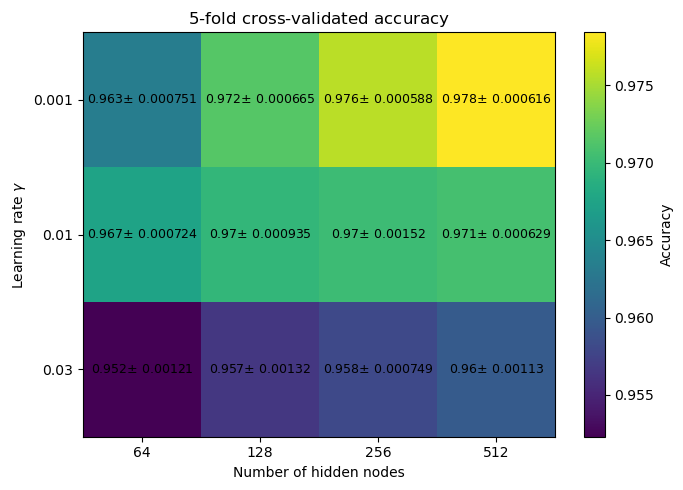

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(acc_c, cmap="viridis", aspect="auto")
ax.set_yticks(np.arange(len(gammas_c)))
ax.set_yticklabels([f"{value:g}" for value in gammas_c])
ax.set_xticks(np.arange(len(hiddens_c)))
ax.set_xticklabels([f"{value:g}" for value in hiddens_c])
ax.set_ylabel("Learning rate $\\gamma$")
ax.set_xlabel("Number of hidden nodes")
ax.set_title("$5$-fold cross-validated accuracy")


for row in range(acc_c.shape[0]):
    for col in range(acc_c.shape[1]):
        label = f"{acc_c[row, col]:.3g}$\\pm$ {se_c[row,col]:.3g}"
        ax.text(col, row, label, ha="center", va="center", fontsize = 9, color="black", linespacing = 1.1)

fig.colorbar(heatmap, ax=ax, label="Accuracy")
fig.tight_layout()
plt.show()

The $1$ standard error rule, doesn't help us choose here, as the best model lies well over one standard error over the rest. We choose $\gamma = 10^{-3}$ and a width of $512$.

We now check regularization and number of epochs.

In [16]:
epochs_c = [15, 20, 25]
lambdas_c = [1e-5, 1e-3, 1e-1]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(gamma = 1e-3, hidden = 512, batch_size = 256), {"epochs": epochs_c, "lmbda": lambdas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)

,estimator,"EstimatorClas...1, hidden=512)"
,param_grid,"{'epochs': [15, 20, ...], 'lmbda': [1e-05, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,hidden,512


In [17]:
print(f"{len(epochs_c) * len(lambdas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_
shape_c = (len(epochs_c), len(lambdas_c))                    
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)

45 training runs in 3090 s


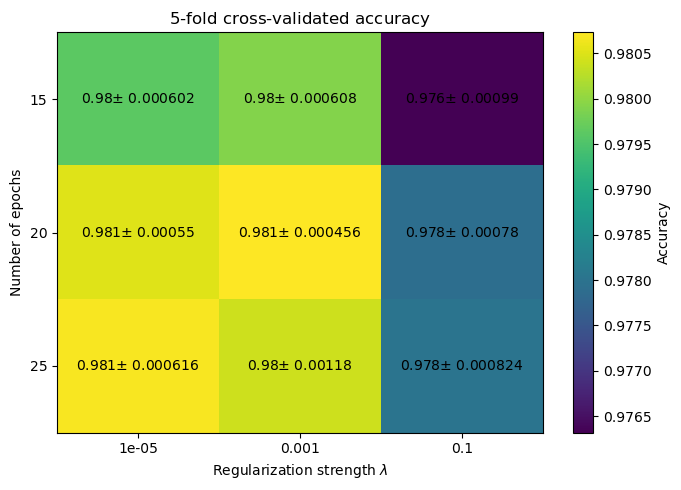

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(acc_c, cmap="viridis", aspect="auto")
ax.set_xticks(np.arange(len(lambdas_c)))
ax.set_xticklabels([f"{value:g}" for value in lambdas_c])
ax.set_yticks(np.arange(len(epochs_c)))
ax.set_yticklabels([f"{value:g}" for value in epochs_c])
ax.set_xlabel("Regularization strength $\\lambda$")
ax.set_ylabel("Number of epochs")
ax.set_title("$5$-fold cross-validated accuracy")


for row in range(acc_c.shape[0]):
    for col in range(acc_c.shape[1]):
        color = "black"
        ax.text(col, row, f"{acc_c[row, col]:.3g}$\\pm$ {se_c[row,col]:.3g}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Accuracy")
fig.tight_layout()
plt.show()

In [11]:
lambdas_c = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(epochs = 25, gamma = 1e-3, hidden = 256, batch_size = 256), {"lmbda": lambdas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)
print(f"{len(lambdas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_                    
acc_c = rc["mean_test_score"]
se_c = rc["std_test_score"] / np.sqrt(k - 1)

40 training runs in 2176 s


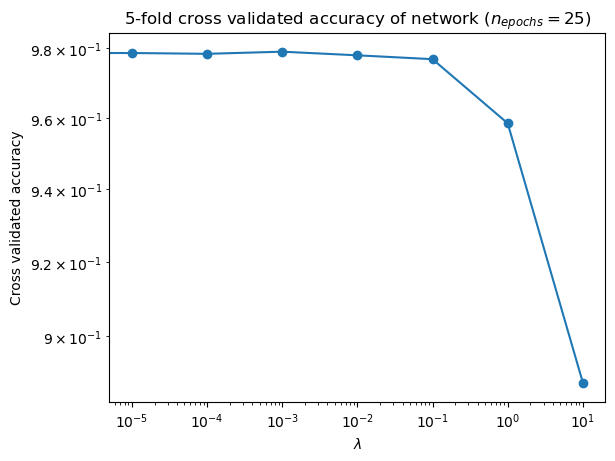

In [14]:
plt.errorbar(lambdas_c, acc_c, fmt = "-o", yerr = se_c, ecolor = "orange")
plt.xlabel("$\\lambda$")
plt.ylabel("Cross validated accuracy")
plt.xscale("log")
plt.yscale("log")
plt.title("$5$-fold cross validated accuracy of network ($n_{epochs} = 25$)")
plt.show()

In [5]:
epochs_c = [10, 15, 20, 25, 30]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(gamma = 1e-3, hidden = 256, batch_size = 256), {"epochs": epochs_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)
print(f"{len(epochs_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_                    
acc_c = rc["mean_test_score"]
se_c = rc["std_test_score"] / np.sqrt(k - 1)

25 training runs in 1176 s


In [8]:
acc_t = rc["mean_train_score"]
se_t = rc["std_test_score"] / np.sqrt(k - 1)

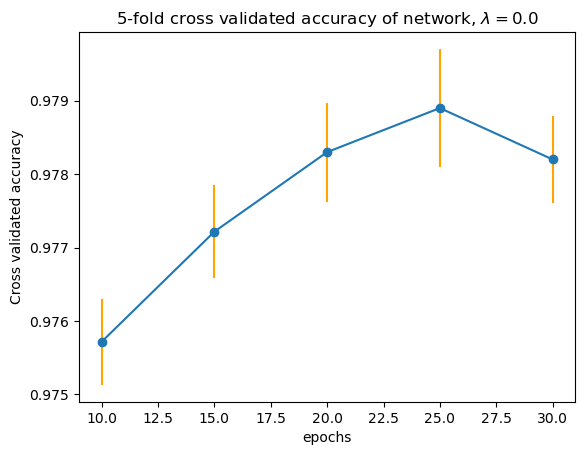

In [12]:
plt.errorbar(epochs_c, acc_c, fmt = "-o", yerr = se_c, ecolor = "orange", label = "test accuracy")
plt.xlabel("epochs")
plt.ylabel("Cross validated accuracy")
plt.title("$5$-fold cross validated accuracy of network, $\\lambda = 0.0$")
plt.show()

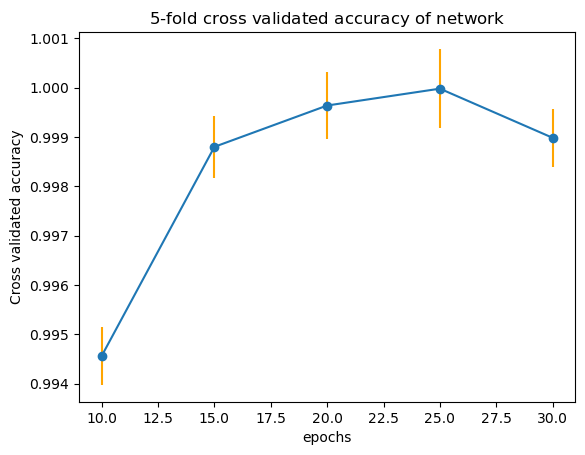

In [10]:
plt.errorbar(epochs_c, acc_t, fmt = "-o", yerr = se_t, ecolor = "orange", label = "training accuracy")
plt.xlabel("epochs")
plt.ylabel("Cross validated accuracy")
plt.title("$5$-fold cross validated accuracy of network")
plt.show()